In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("log_grid_sir.csv", sep=";", skiprows=1)
coords = df["model_name"].str.extract(r"\((-?\d+),(-?\d+)\)")
df["x"] = coords[0].astype(int)
df["y"] = coords[1].astype(int)

In [2]:
cols = df["data"].str.strip("<>").str.split(",", expand=True).astype(float)
df[["c0", "c1", "c2", "c3"]] = cols

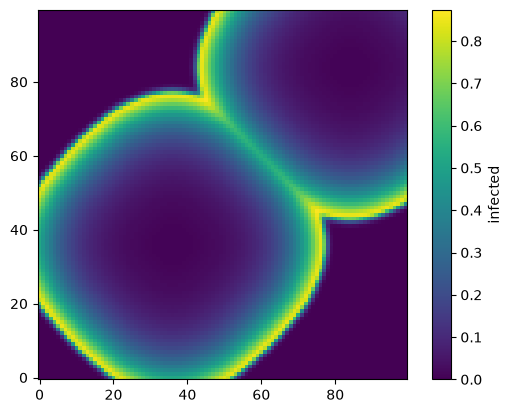

In [3]:
def grid_at(df, t, col="c2"):
    snap = df[df["time"] <= t].drop_duplicates(["x", "y"], keep="last")
    grid = np.full((100, 100), np.nan)
    grid[snap["y"] + 24, snap["x"] + 24] = snap[col]
    return grid

vmax = df["c2"].max()
plt.imshow(grid_at(df, 105), origin="lower", vmin=0, vmax=vmax)
plt.colorbar(label="infected")
plt.show()

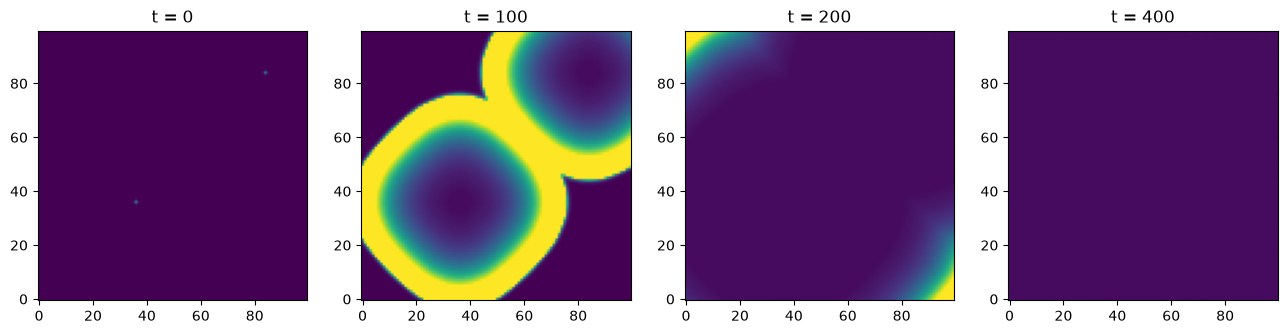

In [4]:
times = [0, 100, 200, 400]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, t in zip(axes, times):
    ax.imshow(grid_at(df, t), origin="lower", vmin=0, vmax=0.36)
    ax.set_title(f"t = {t}")
plt.show()

In [5]:
df[(df["x"] == 36) & (df["y"] == 36)][["time", "c1", "c2", "c3"]].head(20)

,time,c1,c2,c3
2441,0,1.000,0.000,0.000
14882,0,1.000,0.000,0.000
14883,0,1.000,0.000,0.000
433618,87,1.000,0.000,0.000
446069,88,0.998,0.002,0.000
458738,89,0.998,0.002,0.000
458739,89,0.988,0.012,0.000
471626,90,0.988,0.012,0.000
471627,90,0.955,0.044,0.001
484697,91,0.955,0.044,0.001
